In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries updated 1")


Libraries updated 1


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

print("Libraries updated 2")


Libraries updated 2


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from micromlgen import port
from micromlgen import platforms

print("Libraries updated 3")


Libraries updated 3


In [4]:
seed = 7
classmap = {1: 'Ragi', 2: 'Rice', 3: 'Maize'}

print(platforms.ALLOWED_CLASSIFIERS)


['SVC', 'OneClassSVM', 'RVC', 'SEFR', 'DecisionTreeClassifier', 'DecisionTreeRegressor', 'RandomForestClassifier', 'RandomForestRegressor', 'GaussianNB', 'LogisticRegression', 'PCA', 'PrincipalFFT', 'LinearRegression', 'XGBClassifier']


In [5]:
# EDA --> Exploratory Data Analysis

df = pd.read_csv('Crop Prediction Soil.csv')
df.shape


(219, 8)

In [6]:
df.columns


Index(['State', 'District', 'Soil', 'Temperature', 'Humidity', 'SoilMoisture',
       'Rainfall', 'CropLabel'],
      dtype='str')

In [7]:
df.head()


,State,District,Soil,Temperature,Humidity,SoilMoisture,Rainfall,CropLabel
0,Karnataka,Chikabalapura,Black soil,32,44,150,160,Ragi
1,Karnataka,Chikabalapura,Black soil,26,46,240,235,Rice
2,Karnataka,Chikabalapura,Black soil,36,44,135,120,Maize
3,Karnataka,Chikabalapura,Black soil,27,58,280,241,Rice
4,Karnataka,Chikabalapura,Black soil,24,63,279,245,Rice


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 219 entries, 0 to 218
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   State         219 non-null    str  
 1   District      219 non-null    str  
 2   Soil          219 non-null    str  
 3   Temperature   219 non-null    int64
 4   Humidity      219 non-null    int64
 5   SoilMoisture  219 non-null    int64
 6   Rainfall      219 non-null    int64
 7   CropLabel     219 non-null    str  
dtypes: int64(4), str(4)
memory usage: 22.0 KB


In [9]:
df.describe()


,Temperature,Humidity,SoilMoisture,Rainfall
count,219.000000,219.000000,219.000000,219.000000
mean,32.146119,54.812785,165.031963,170.643836
std,4.729046,8.734967,79.276221,70.831439
min,24.000000,40.000000,30.000000,70.000000
25%,28.000000,47.500000,98.500000,100.000000
50%,33.000000,54.000000,171.000000,171.000000
75%,36.000000,63.000000,243.000000,241.500000
max,40.000000,70.000000,280.000000,279.000000


In [10]:
# Check for output Label, to analyse data is balanced or 
# unbalanced wrt to output Label

df['CropLabel'].value_counts()


CropLabel
Maize    80
Rice     78
Ragi     61
Name: count, dtype: int64

In [11]:
df.drop(["State","District","Soil"], 
                axis=1, errors="ignore", inplace=True)


In [12]:
df.isnull().sum()


Temperature     0
Humidity        0
SoilMoisture    0
Rainfall        0
CropLabel       0
dtype: int64

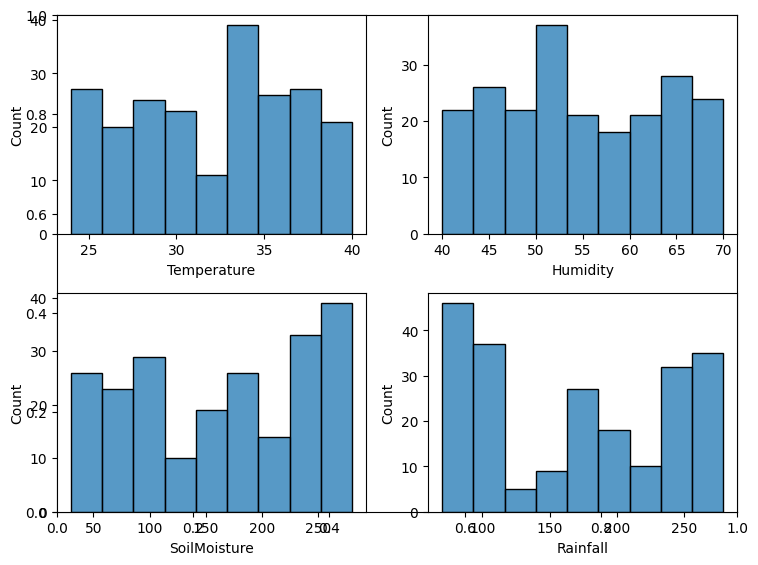

In [13]:
features = ['Temperature', 'Humidity', 'SoilMoisture', 'Rainfall']

plt.subplots(figsize=(8, 6))
for i, col in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.histplot(df[col])

plt.tight_layout()
plt.savefig('Histogram Plot')
plt.show()


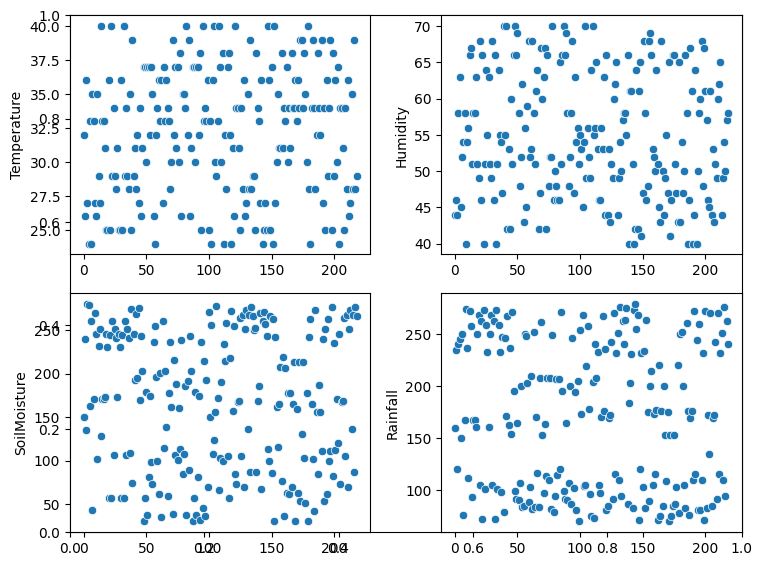

In [14]:
features = ['Temperature', 'Humidity', 'SoilMoisture', 'Rainfall']

plt.subplots(figsize=(8, 6))
for i, col in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.scatterplot(df[col])

plt.tight_layout()
plt.savefig('Scatter Plot')
plt.show()


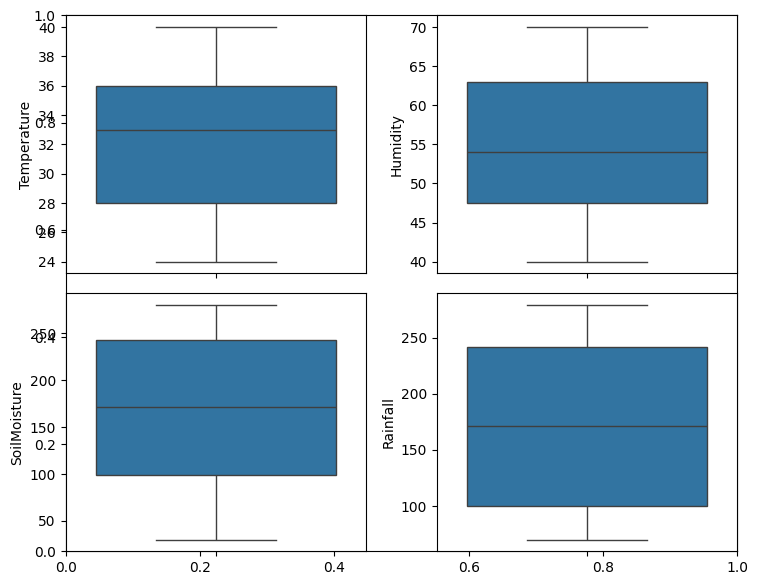

In [15]:
features = ['Temperature', 'Humidity', 'SoilMoisture', 'Rainfall']

plt.subplots(figsize=(8, 6))
for i, col in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(df[col])

plt.tight_layout()
plt.savefig('Box Plot')
plt.show()


In [16]:
# It has all the information (Age, Class, Port) they need to study.
X = df.drop("CropLabel", axis=1) 

y = df["CropLabel"] # It shows the final results (Survived or Not)


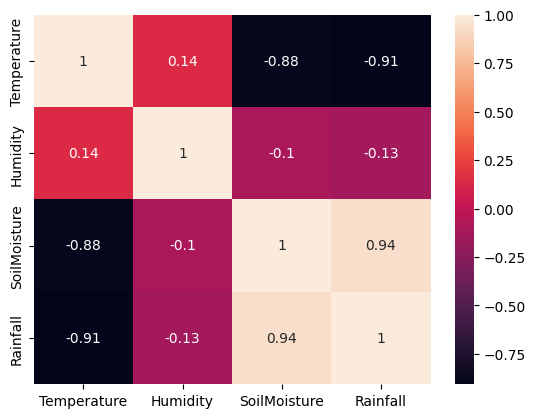

In [17]:
df.drop(["CropLabel"], axis=1, errors="ignore", inplace=True)

sns.heatmap(df.corr(), annot=True, cbar=True)
plt.savefig('HeatMap')
plt.show()


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(len(X_train))
print(len(y_train))
print(len(X_test))
print(len(y_test))


164
164
55
55


In [19]:
# Logistic Regression
LR = LogisticRegression()
classifier = LR.fit(X_train,y_train)
pred = LR.predict(X_test)
print("LR Accuracy_score:", accuracy_score(y_test,pred)*100)


LR Accuracy_score: 90.9090909090909


C:\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
# SVM
SVC = SVC(kernel = 'linear')
classifier = SVC.fit(X_train,y_train)
pred = SVC.predict(X_test)
print("SVC Accuracy_score:", accuracy_score(y_test,pred)*100)
print(pred[0:5], '\n')


SVC Accuracy_score: 92.72727272727272
['Ragi' 'Maize' 'Maize' 'Rice' 'Ragi'] 



In [21]:
# Random Forest Classifier
RF = RandomForestClassifier(20, max_depth=10)
classifier = RF.fit(X_train,y_train)
pred = RF.predict(X_test)
print("RF Accuracy_score:", accuracy_score(y_test,pred)*100)
print(pred[0:5], '\n')


RF Accuracy_score: 92.72727272727272
['Ragi' 'Maize' 'Maize' 'Rice' 'Ragi'] 



In [22]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# model create
model = GaussianNB()

#Model fitting
classifier = model.fit(X_train, y_train)

#testing the model
pred = model.predict(X_test)

#model accuracy
print(accuracy_score(y_test, pred)*100)


92.72727272727272


In [23]:
from sklearn import metrics
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred)
print(cm,'\n')

# cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = cm,
#											display_labels = [False, True])

# cm_display.plot()
# plt.savefig('Confusion Matrix')


[[19  0  0]
 [ 1 17  0]
 [ 2  1 15]] 



In [24]:
from sklearn.metrics import classification_report

print("\nClassification Report :\n")
print(classification_report(y_test, pred))



Classification Report :

              precision    recall  f1-score   support

       Maize       0.86      1.00      0.93        19
        Ragi       0.94      0.94      0.94        18
        Rice       1.00      0.83      0.91        18

    accuracy                           0.93        55
   macro avg       0.94      0.93      0.93        55
weighted avg       0.93      0.93      0.93        55



In [25]:
print(y_test[1:10])
print(pred[1:10])


93     Maize
216    Maize
217     Rice
15      Ragi
104    Maize
171    Maize
208     Rice
75     Maize
141     Rice
Name: CropLabel, dtype: str
['Maize' 'Maize' 'Rice' 'Ragi' 'Maize' 'Maize' 'Rice' 'Maize' 'Rice']


In [26]:
c_code = port(classifier, classmap=classmap)
# print(c_code)

filename = "AgriGaussianNBmodelLab.h"
with open(filename, 'w') as f:
    f.write(c_code)


In [27]:
print("Project End")


Project End
